# M5 Demand Forecasting → Inventory Decisions
## Notebook 02 — Exploratory Data Analysis

**Goal:** Understand how demand behaves for Texas FOODS before modelling. Every chart answers a question, and every finding is tied to a modelling or inventory decision.

**Input:** `data/processed/m5_tx_foods_long.parquet` (from Notebook 01)

| Step | Question |
|---|---|
| 1 | How do sales evolve over time? Any unusual days? |
| 2 | Are there weekly and yearly patterns? |
| 3 | How intermittent is demand (how often do items sell zero)? |
| 4 | Do SNAP days, events, and prices move sales? |
| 5 | How different are stores and departments? |
| — | Summary: findings → modelling decisions |

## Setup — Load Data & Chart Style

In [14]:
from google.colab import drive
drive.mount('/content/drive')

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

PROJECT_DIR = '/content/drive/MyDrive/m5-inventory'
DATA_FILE   = os.path.join(PROJECT_DIR, 'data', 'processed', 'm5_tx_foods_long.parquet')
FIG_DIR     = os.path.join(PROJECT_DIR, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_parquet(DATA_FILE)

print(f"{len(df):,} rows | {df.shape[1]} columns | {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"Dates: {df['date'].min().date()} → {df['date'].max().date()}")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
6,773,457 rows | 13 columns | 183.0 MB
Dates: 2011-01-29 → 2016-05-22


,item_id,dept_id,store_id,d,sales,date,wm_yr_wk,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price
0,FOODS_1_001,FOODS_1,TX_1,1,0,2011-01-29,11101,NaN,NaN,NaN,NaN,0,2.0
1,FOODS_1_001,FOODS_1,TX_1,2,1,2011-01-30,11101,NaN,NaN,NaN,NaN,0,2.0
2,FOODS_1_001,FOODS_1,TX_1,3,1,2011-01-31,11101,NaN,NaN,NaN,NaN,0,2.0
3,FOODS_1_001,FOODS_1,TX_1,4,0,2011-02-01,11101,NaN,NaN,NaN,NaN,1,2.0
4,FOODS_1_001,FOODS_1,TX_1,5,0,2011-02-02,11101,NaN,NaN,NaN,NaN,0,2.0


In [15]:
# One consistent, clean style for every chart in the project
plt.rcParams.update({
    'figure.dpi': 110,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.8,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'lines.linewidth': 2,
    'legend.frameon': False,
})

# Fixed colors: each one always means the same thing across the project
BLUE  = '#2a78d6'   # main series
GRAY  = '#b5b4ad'   # raw / background context
STORE_COLORS = {'TX_1': '#2a78d6', 'TX_2': '#eb6834', 'TX_3': '#1baf7a'}

def save_fig(fig, name):
    """Save a chart to reports/figures/ as a PNG (for the README and dashboard)."""
    path = os.path.join(FIG_DIR, f'{name}.png')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print("Saved:", path)

## Step 1 — Sales Over Time

**Question:** How do total sales evolve over time, and are there unusual days?

Because pre-launch rows were removed, the number of products on the shelf grows over time. A rising total could mean higher demand *per product* or simply *more products*, so we split the total into: **units sold**, **active products**, and **units per active product**. A 28-day rolling average (4 full weeks, matching our forecast horizon) smooths out day-to-day noise.

In [16]:
daily = df.groupby('date').agg(
    total_units   = ('sales', 'sum'),
    active_series = ('sales', 'size'),
)
daily['units_per_series'] = daily['total_units'] / daily['active_series']

print(f"{len(daily):,} days")
daily.describe().round(1)

1,941 days


,total_units,active_series,units_per_series
count,1941.0,1941.0,1941.0
mean,6786.2,3489.7,2.0
std,1338.8,725.1,0.5
min,2.0,1805.0,0.0
25%,5864.0,2916.0,1.6
50%,6635.0,3611.0,1.9
75%,7658.0,4237.0,2.3
max,14333.0,4311.0,4.5


Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_01_sales_over_time.png


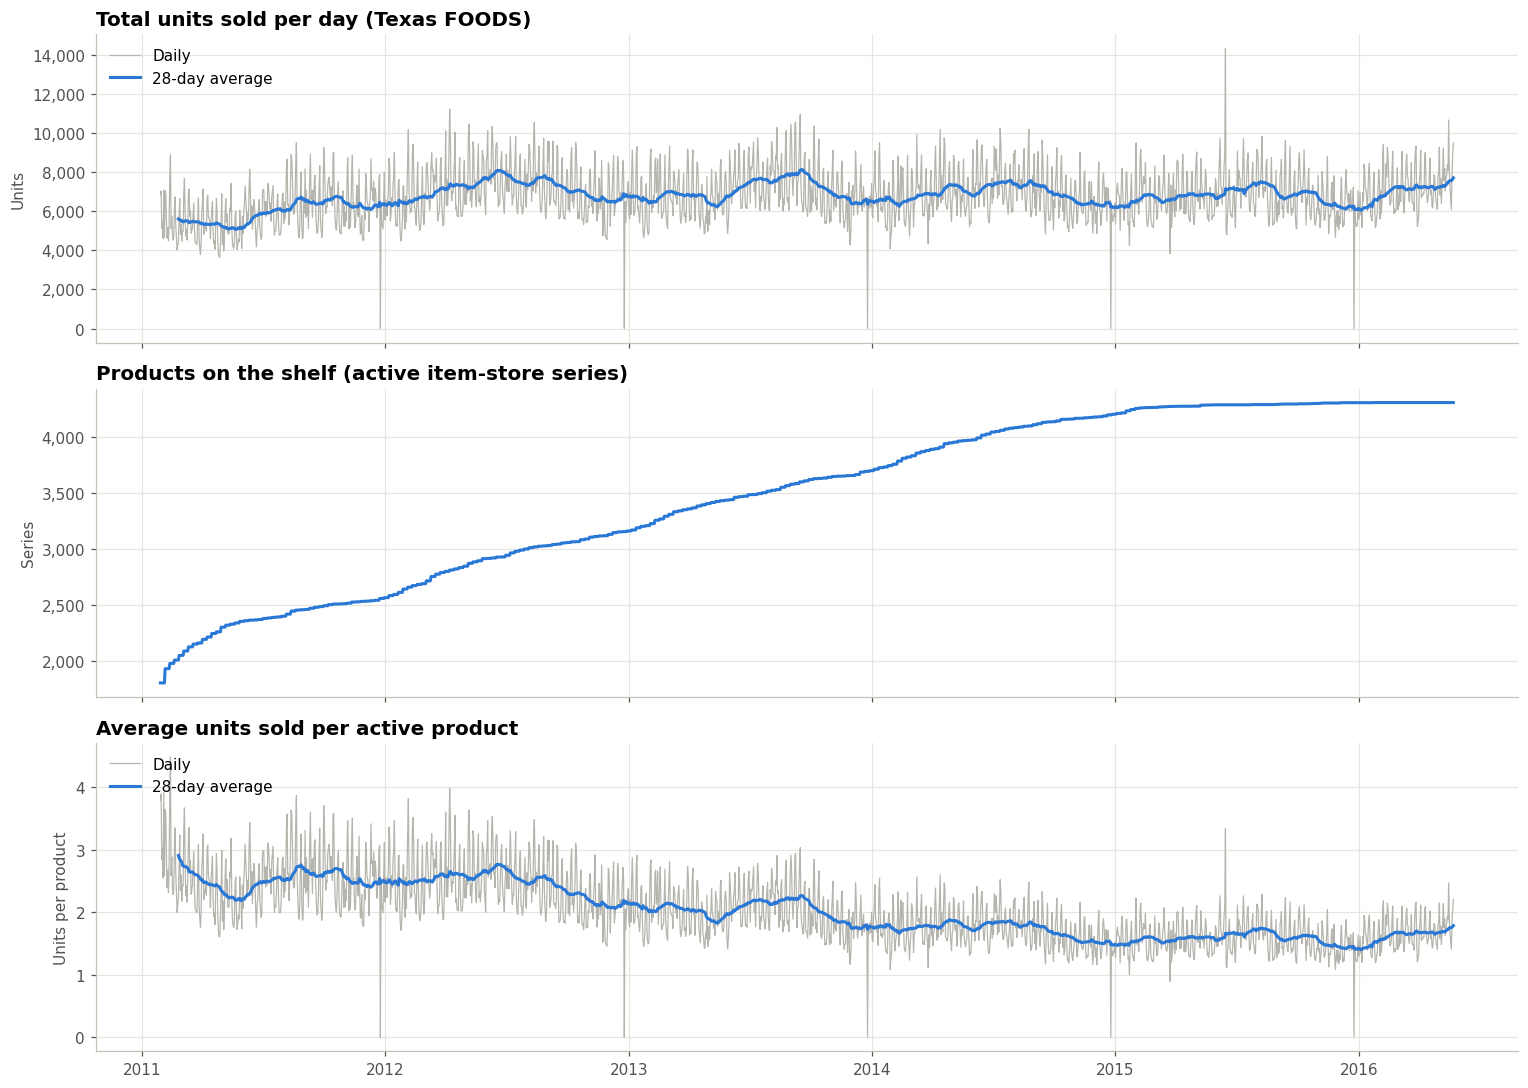

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Panel 1: total units sold
ax = axes[0]
ax.plot(daily.index, daily['total_units'], color=GRAY, linewidth=0.8, label='Daily')
ax.plot(daily.index, daily['total_units'].rolling(28).mean(), color=BLUE, label='28-day average')
ax.set_title('Total units sold per day (Texas FOODS)')
ax.set_ylabel('Units')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(loc='upper left')

# Panel 2: products on the shelf
ax = axes[1]
ax.plot(daily.index, daily['active_series'], color=BLUE)
ax.set_title('Products on the shelf (active item-store series)')
ax.set_ylabel('Series')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

# Panel 3: average units per product
ax = axes[2]
ax.plot(daily.index, daily['units_per_series'], color=GRAY, linewidth=0.8, label='Daily')
ax.plot(daily.index, daily['units_per_series'].rolling(28).mean(), color=BLUE, label='28-day average')
ax.set_title('Average units sold per active product')
ax.set_ylabel('Units per product')
ax.legend(loc='upper left')

fig.tight_layout()
save_fig(fig, '02_01_sales_over_time')
plt.show()

In [18]:
# The 6 days with the lowest total sales
daily.nsmallest(6, 'total_units')

,total_units,active_series,units_per_series
date,,,
2011-12-25,2,2560,0.000781
2012-12-25,2,3157,0.000634
2015-12-25,4,4310,0.000928
2013-12-25,13,3696,0.003517
2014-12-25,13,4201,0.003095
2011-04-28,3636,2261,1.608138


In [19]:
spike_date = daily['total_units'].idxmax()
print(f"Highest-sales day: {spike_date.date()} ({daily.loc[spike_date, 'total_units']:,} units)\n")

# Each product's normal average daily sales, to compare against
typical = (
    df.groupby(['item_id', 'store_id'], observed=True)['sales']
      .mean()
      .rename('typical_daily_avg')
      .round(1)
)

# The 5 products that sold the most on that day, next to their normal average
top = df.loc[df['date'] == spike_date, ['item_id', 'store_id', 'sales', 'sell_price']].nlargest(5, 'sales')
top.join(typical, on=['item_id', 'store_id'])

Highest-sales day: 2015-06-15 (14,333 units)



,item_id,store_id,sales,sell_price,typical_daily_avg
5635287,FOODS_3_090,TX_3,225,1.48,60.2
5684116,FOODS_3_120,TX_3,145,4.98,11.4
4186913,FOODS_3_587,TX_2,131,2.48,26.2
3659843,FOODS_3_252,TX_2,128,1.58,59.6
4525161,FOODS_3_811,TX_2,107,1.88,21.3


In [20]:
# Total units per store per day (rows = dates, columns = stores)
store_daily = df.groupby(['date', 'store_id'], observed=True)['sales'].sum().unstack()

# The week before and after the spike
store_daily.loc['2015-06-08':'2015-06-21']

store_id,TX_1,TX_2,TX_3
date,,,
2015-06-08,2188,2551,2573
2015-06-09,2214,2512,2397
2015-06-10,1981,2244,2126
2015-06-11,2013,2639,2547
2015-06-12,2004,2723,2543
2015-06-13,2532,2934,2846
2015-06-14,2813,3045,3051
2015-06-15,3978,5251,5104
2015-06-16,1852,1507,1658


### Step 1 — Takeaways

- **Christmas = store closed.** Dec 25 has 2–13 total units every year vs. 3,600+ on the next-lowest day. → *Remove Christmas from training and evaluation; it is not a demand signal.*
- **The catalog doubled, total sales did not.** Active products grew ~1,800 → ~4,310, while total daily sales stayed roughly flat (~6,000–8,000). Average units per product fell ~2.7 → ~1.6. *Hypothesis:* later-launched products sell less than the established ones. → *Always analyse per product, not totals.*
- **Yearly seasonality is visible** — a recurring mid-year rise in per-product sales (checked in Step 2).
- **Level drifts over time**, so recent history is most representative. → *Validate on the most recent periods; never shuffle.*
- **One-off spike on 2015-06-15** (14,333 units, ~2× a normal day). **All three stores** roughly doubled vs. the previous Monday (TX_1 1.8×, TX_2 2.1×, TX_3 2.0×), and the next two days fell *below* normal before recovering — the classic stockpiling shape. It falls the day before **Tropical Storm Bill** made landfall in Texas (2015-06-16). Demand was pulled forward, not just added. → *Real demand, but not predictable from our features; kept in the data and expected to show up as a forecast miss. Not in our final test window.*

## Step 2 — Weekly & Yearly Patterns

**Question:** Do sales follow a weekly rhythm and a yearly season?

To get a fair comparison we:
- use **units per active product** (removes catalog growth),
- use only **complete years 2012–2015** (each month appears equally often),
- express each day as an **index vs. its own year's average** (1.0 = a normal day; removes the downward trend),
- exclude **Christmas** (store closed).

In [21]:
import seaborn as sns

is_christmas = (daily.index.month == 12) & (daily.index.day == 25)
full_years = daily.index.year.isin([2012, 2013, 2014, 2015])

season = daily.loc[full_years & ~is_christmas, ['units_per_series']].copy()
season['year'] = season.index.year

# Index each day against the average day of its own year (1.0 = normal day)
season['index'] = season['units_per_series'] / season.groupby('year')['units_per_series'].transform('mean')

season['weekday'] = season.index.day_name().str[:3]     # 'Mon', 'Tue', ...
season['month']   = season.index.month_name().str[:3]   # 'Jan', 'Feb', ...

WEEKDAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTHS   = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

print(f"{len(season):,} days used (2012–2015, Christmas excluded)")
season.head()

1,457 days used (2012–2015, Christmas excluded)


,units_per_series,year,index,weekday,month
date,,,,,
2012-01-01,2.165173,2012,0.882777,Sun,Jan
2012-01-02,2.559018,2012,1.043354,Mon,Jan
2012-01-03,2.440982,2012,0.995228,Tue,Jan
2012-01-04,2.240748,2012,0.913590,Wed,Jan
2012-01-05,2.518115,2012,1.026676,Thu,Jan


Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_02_weekly_yearly_seasonality.png


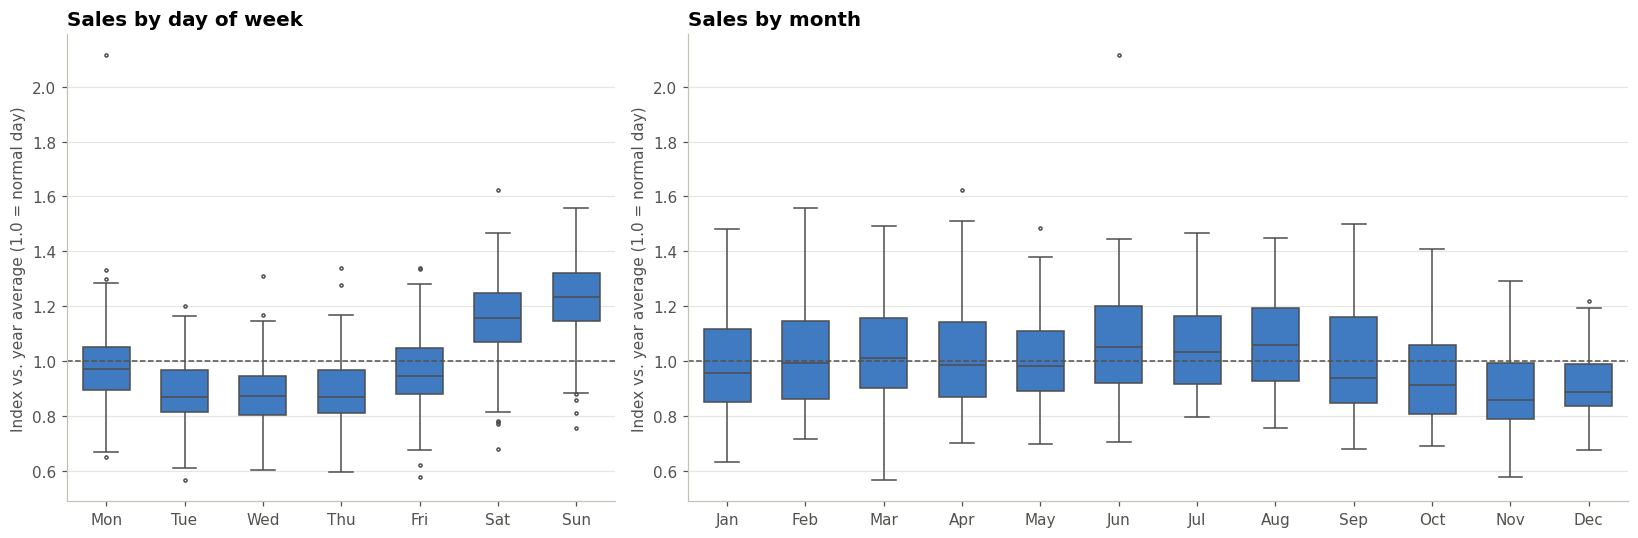

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [7, 12]})

sns.boxplot(data=season, x='weekday', y='index', order=WEEKDAYS,
            color=BLUE, width=0.6, linewidth=1, fliersize=2, ax=axes[0])
axes[0].set_title('Sales by day of week')

sns.boxplot(data=season, x='month', y='index', order=MONTHS,
            color=BLUE, width=0.6, linewidth=1, fliersize=2, ax=axes[1])
axes[1].set_title('Sales by month')

for ax in axes:
    ax.axhline(1.0, color='#52514e', linestyle='--', linewidth=1)   # 1.0 = a normal day
    ax.set_xlabel('')
    ax.set_ylabel('Index vs. year average (1.0 = normal day)')

fig.tight_layout()
save_fig(fig, '02_02_weekly_yearly_seasonality')
plt.show()

In [23]:
weekday_index = season.groupby('weekday')['index'].mean().reindex(WEEKDAYS)
month_index   = season.groupby('month')['index'].mean().reindex(MONTHS)

print("Average index by weekday (1.00 = normal day):")
print(weekday_index.round(2).to_string())

print("\nAverage index by month:")
print(month_index.round(2).to_string())

print(f"\nBusiest weekday vs. quietest: {weekday_index.max() / weekday_index.min() - 1:.0%} more units")
print(f"Busiest month vs. quietest:   {month_index.max() / month_index.min() - 1:.0%} more units")

Average index by weekday (1.00 = normal day):
weekday
Mon    0.99
Tue    0.89
Wed    0.89
Thu    0.89
Fri    0.96
Sat    1.15
Sun    1.23

Average index by month:
month
Jan    0.99
Feb    1.02
Mar    1.03
Apr    1.02
May    1.01
Jun    1.07
Jul    1.05
Aug    1.06
Sep    1.00
Oct    0.94
Nov    0.89
Dec    0.91

Busiest weekday vs. quietest: 39% more units
Busiest month vs. quietest:   21% more units


In [24]:
# Each product's launch date = its first row (pre-launch rows were removed in Notebook 01)
first_date = df.groupby(['item_id', 'store_id'], observed=True)['date'].min()
print(f"Established products (launched before 2012): {(first_date < '2012-01-01').sum():,} of {len(first_date):,}")

# Give every row its own product's launch date, then keep only established products
launch_date = df.groupby(['item_id', 'store_id'], observed=True)['date'].transform('min')
est = df.loc[launch_date < '2012-01-01', ['date', 'sales']]

# Average units per product per day, for this FIXED set of products
est_daily = est.groupby('date')['sales'].mean().to_frame('units_per_series')

# Same recipe as Code cell 7: full years, no Christmas, index vs. own year's average
d = est_daily.index
keep = d.year.isin([2012, 2013, 2014, 2015]) & ~((d.month == 12) & (d.day == 25))
est_season = est_daily.loc[keep].copy()
est_season['year'] = est_season.index.year
est_season['index'] = est_season['units_per_series'] / est_season.groupby('year')['units_per_series'].transform('mean')
est_season['weekday'] = est_season.index.day_name().str[:3]
est_season['month'] = est_season.index.month_name().str[:3]

# Compare: all products vs. established only
compare_month = pd.DataFrame({
    'all_products':     month_index,
    'established_only': est_season.groupby('month')['index'].mean().reindex(MONTHS),
})
compare_month['difference'] = compare_month['established_only'] - compare_month['all_products']

compare_weekday = pd.DataFrame({
    'all_products':     weekday_index,
    'established_only': est_season.groupby('weekday')['index'].mean().reindex(WEEKDAYS),
})

print("\nMONTH index:")
print(compare_month.round(2).to_string())
print("\nWEEKDAY index:")
print(compare_weekday.round(2).to_string())

del est, launch_date
_ = gc.collect()

Established products (launched before 2012): 2,567 of 4,311

MONTH index:
       all_products  established_only  difference
month                                            
Jan            0.99              0.96       -0.03
Feb            1.02              0.99       -0.03
Mar            1.03              0.99       -0.03
Apr            1.02              0.99       -0.03
May            1.01              1.00       -0.01
Jun            1.07              1.09        0.02
Jul            1.05              1.08        0.03
Aug            1.06              1.10        0.04
Sep            1.00              1.03        0.02
Oct            0.94              0.94       -0.00
Nov            0.89              0.90        0.02
Dec            0.91              0.92        0.01

WEEKDAY index:
         all_products  established_only
weekday                                
Mon              0.99              0.98
Tue              0.89              0.89
Wed              0.89              0.88
Thu       

### Step 2 — Takeaways

- **Strong weekly pattern.** Sunday (1.23) and Saturday (1.15) are the peaks; Tue–Thu (0.89) are the troughs — **Sunday sells ~39% more than midweek**, and the pattern holds almost every week (weekend boxes sit entirely above 1.0).
  → *Day of week is a must-have feature. Our 28-day horizon is exactly 4 weeks, so "same day 4 weeks ago" always lands on the same weekday — a natural seasonal-naive baseline. Stock must be on the shelf before the weekend.*
- **Mild yearly season.** Summer (Jun–Aug) runs **~8–10% above** normal and Oct–Dec **~6–10% below**. Month medians overlap heavily, so this is a much weaker effect than day of week.
  → *Month / day-of-year is a useful but secondary feature.*
- **Verified against catalog-growth bias.** Repeating the analysis on a fixed set of 2,567 products launched before 2012 changes monthly indices by at most ±0.04 and weekday indices by ±0.02. The seasonal patterns are real, not an artifact of new product launches.

## Step 3 — Intermittent Demand (the Zeros Problem)

**Question:** How often do individual products sell zero, and how does that vary across products?

Totals hide this: at the item-store-day level, many products sell 0–2 units on most days. This matters for every later stage — models can look "accurate" by predicting ~0, percentage metrics like MAPE break on zero sales, quantile forecasts become essential, and slow and fast sellers need different inventory rules.

We build a one-row-per-series summary (launch date, average daily sales, share of zero-sales days) and use it to measure intermittency and to test the Step 1 hypothesis that later-launched products sell less.

In [25]:
# Temporary helper column: 1 if the product sold nothing that day
df['is_zero'] = (df['sales'] == 0).astype('int8')

series_stats = df.groupby(['item_id', 'store_id'], observed=True).agg(
    dept_id     = ('dept_id', 'first'),
    launch_date = ('date', 'min'),
    n_days      = ('sales', 'size'),
    total_units = ('sales', 'sum'),
    mean_daily  = ('sales', 'mean'),
    zero_share  = ('is_zero', 'mean'),
).reset_index()

df = df.drop(columns='is_zero')
series_stats['launch_year'] = series_stats['launch_date'].dt.year

print(f"{len(series_stats):,} product-store series")
series_stats.sort_values('total_units', ascending=False).head()

4,311 product-store series


,item_id,store_id,dept_id,launch_date,n_days,total_units,mean_daily,zero_share,launch_year
3595,FOODS_3_586,TX_2,FOODS_3,2011-01-29,1941,195120,100.525502,0.004122,2011
3596,FOODS_3_586,TX_3,FOODS_3,2011-01-29,1941,151862,78.239052,0.003606,2011
2107,FOODS_3_090,TX_2,FOODS_3,2011-01-29,1941,121275,62.480680,0.242658,2011
2108,FOODS_3_090,TX_3,FOODS_3,2011-01-29,1941,116773,60.161257,0.243174,2011
2593,FOODS_3_252,TX_2,FOODS_3,2011-01-29,1941,115613,59.563627,0.002061,2011


Share of all item-store-days with zero sales: 54.7%

Share of zero-sales days per product:
count    4311.00
mean        0.56
std         0.23
min         0.00
10%         0.22
25%         0.39
50%         0.59
75%         0.75
90%         0.84
max         0.98
Products with zero sales on more than 25% of days: 87.6%
Products with zero sales on more than 50% of days: 62.4%
Products with zero sales on more than 75% of days: 24.4%
Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_03_zero_sales_distribution.png


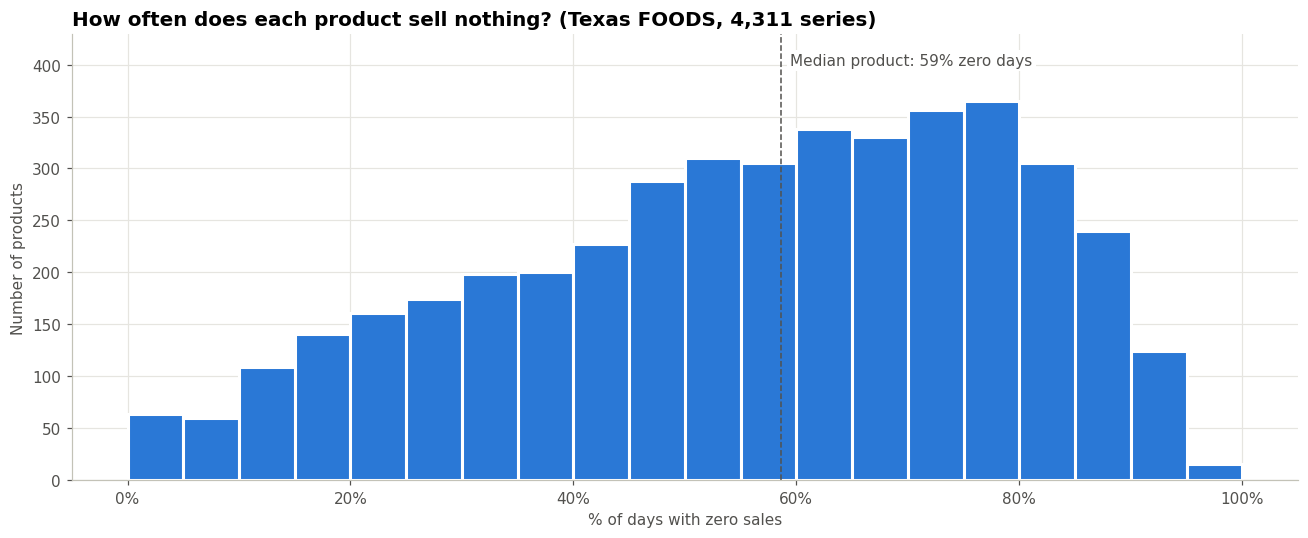

In [28]:
overall_zero = (df['sales'] == 0).mean()
print(f"Share of all item-store-days with zero sales: {overall_zero:.1%}\n")

print("Share of zero-sales days per product:")
print(series_stats['zero_share'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())

for cutoff in [0.25, 0.50, 0.75]:
    share = (series_stats['zero_share'] > cutoff).mean()
    print(f"Products with zero sales on more than {cutoff:.0%} of days: {share:.1%}")

# Histogram: how many products have each zero-share level
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(series_stats['zero_share'] * 100, bins=np.arange(0, 105, 5),
        color=BLUE, edgecolor='white', linewidth=2)
median_zero = series_stats['zero_share'].median() * 100
ax.axvline(median_zero, color='#52514e', linestyle='--', linewidth=1)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.annotate(f'Median product: {median_zero:.0f}% zero days',
            xy=(median_zero, ax.get_ylim()[1] * 0.93), xytext=(6, 0),
            textcoords='offset points', color='#52514e',
            bbox=dict(facecolor='white', edgecolor='none', pad=2))
ax.set_title('How often does each product sell nothing? (Texas FOODS, 4,311 series)')
ax.set_xlabel('% of days with zero sales')
ax.set_ylabel('Number of products')
ax.xaxis.set_major_formatter(mticker.PercentFormatter())

fig.tight_layout()
save_fig(fig, '02_03_zero_sales_distribution')
plt.show()

In [29]:
# Compare every product on the SAME period (2015), so each cohort faces the same conditions
in_2015 = df['date'].dt.year == 2015
mean_2015 = (
    df.loc[in_2015]
      .groupby(['item_id', 'store_id'], observed=True)['sales']
      .mean()
      .rename('mean_daily_2015')
)

cohort_df = series_stats.join(mean_2015, on=['item_id', 'store_id'])

# Only products launched by end of 2014, so all of them were on the shelf for all of 2015
cohort = (
    cohort_df[cohort_df['launch_year'] <= 2014]
      .groupby('launch_year')
      .agg(
          products          = ('mean_daily_2015', 'size'),
          mean_units_2015   = ('mean_daily_2015', 'mean'),
          median_units_2015 = ('mean_daily_2015', 'median'),
          median_zero_share = ('zero_share', 'median'),
      )
      .round(2)
)
cohort

,products,mean_units_2015,median_units_2015,median_zero_share
launch_year,,,,
2011,2567,1.83,0.70,0.55
2012,596,1.39,0.56,0.65
2013,539,1.31,0.71,0.59
2014,505,0.88,0.52,0.66


### Step 3 — Findings (part 1)

- **Demand is highly intermittent.** 54.7% of all item-store-days have zero sales; the median product sells nothing on **59%** of its days, and **62%** of products sell nothing on more than half their days. Only ~120 products sell almost every day.
  → *Percentage metrics like MAPE are unusable; quantile (P90) forecasts matter more than averages for slow sellers.*
- **Later launches sell less — confirmed.** Measured in the same year (2015), mean daily sales fall from **1.83** (2011 cohort) to **0.88** (2014 cohort). The median barely changes (0.52–0.71): the gap comes from the 2011 cohort containing the bestsellers, while new launches rarely become stars.
- ⚠️ **Some zeros are stockouts, not zero demand.** FOODS_3_090 averages ~60 units/day yet has zero sales on **24%** of days — implausible as genuine zero demand. We observe *sales*, which equal demand only when stock is available (**censored demand**). Investigated below.

In [30]:
z = df['sales'] == 0

# Is this row the same product-store as the row above?
same_series = (df['item_id'] == df['item_id'].shift()) & (df['store_id'] == df['store_id'].shift())

# A new run starts when zero/non-zero flips, or a new series begins
new_run = (z != z.shift()) | ~same_series
run_id = new_run.cumsum()

# Length of the run each row belongs to; keep only zero-runs
run_length = z.groupby(run_id).transform('size')
zero_run_length = run_length.where(z)

longest = (
    zero_run_length
      .groupby([df['item_id'], df['store_id']], observed=True)
      .max()
      .rename('longest_zero_run')
)

# Attach to the summary table (drop first so the cell is safe to re-run)
series_stats = series_stats.drop(columns='longest_zero_run', errors='ignore')
series_stats = series_stats.join(longest, on=['item_id', 'store_id'])
series_stats['longest_zero_run'] = series_stats['longest_zero_run'].fillna(0).astype(int)

del z, same_series, new_run, run_id, run_length, zero_run_length
_ = gc.collect()

# Fast sellers with suspiciously long zero streaks
fast = series_stats[series_stats['mean_daily'] >= 10]
print(f"Fast sellers (10+ units/day on average): {len(fast)}")
print(f"...of which have a zero streak of 7+ days: {(fast['longest_zero_run'] >= 7).sum()}\n")

fast.sort_values('longest_zero_run', ascending=False)[
    ['item_id', 'store_id', 'mean_daily', 'zero_share', 'longest_zero_run']
].head(10).round(2)

Fast sellers (10+ units/day on average): 109
...of which have a zero streak of 7+ days: 82



,item_id,store_id,mean_daily,zero_share,longest_zero_run
2198,FOODS_3_120,TX_3,11.39,0.44,483
2287,FOODS_3_150,TX_2,12.81,0.31,468
3169,FOODS_3_444,TX_2,11.77,0.57,413
3599,FOODS_3_587,TX_3,21.09,0.20,359
4120,FOODS_3_764,TX_2,10.32,0.18,293
2824,FOODS_3_329,TX_2,13.79,0.24,267
3385,FOODS_3_516,TX_2,10.03,0.16,260
2107,FOODS_3_090,TX_2,62.48,0.24,233
4003,FOODS_3_723,TX_2,17.71,0.24,233
4002,FOODS_3_723,TX_1,16.66,0.24,232


FOODS_3_120 in TX_3: avg 11.4/day, longest zero streak 483 days
Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_04_hidden_stockout_example.png


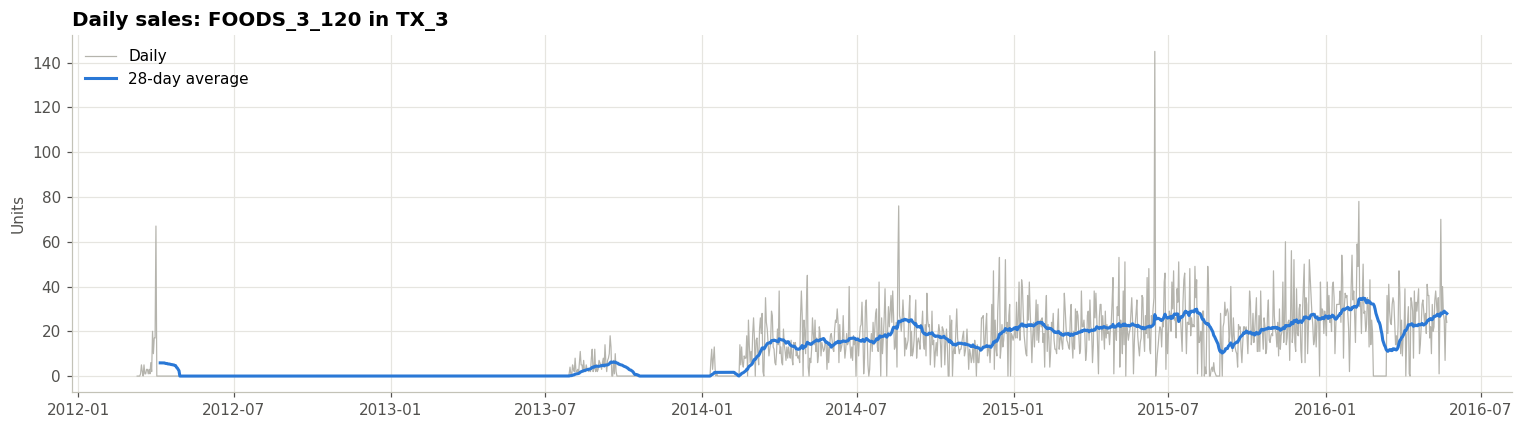

In [31]:
def plot_series(item_id, store_id, start=None, end=None):
    """Plot one product-store's daily sales with a 28-day average."""
    s = df.loc[(df['item_id'] == item_id) & (df['store_id'] == store_id)].set_index('date')['sales']
    s = s.loc[start:end]

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(s.index, s, color=GRAY, linewidth=0.8, label='Daily')
    ax.plot(s.index, s.rolling(28).mean(), color=BLUE, label='28-day average')
    ax.set_title(f'Daily sales: {item_id} in {store_id}')
    ax.set_ylabel('Units')
    ax.legend(loc='upper left')
    fig.tight_layout()
    return fig

worst = fast.sort_values('longest_zero_run', ascending=False).iloc[0]
print(f"{worst['item_id']} in {worst['store_id']}: avg {worst['mean_daily']:.1f}/day, "
      f"longest zero streak {worst['longest_zero_run']} days")

fig = plot_series(worst['item_id'], worst['store_id'])
save_fig(fig, '02_04_hidden_stockout_example')
plt.show()

### Step 3b — Hidden Stockouts & Unavailable Periods

FOODS_3_120 in TX_3 shows two kinds of zeros that are *not* zero demand:
1. **Long dormant stretches** — 483 days of zero sales (mid-2012 → late 2013) despite having a price: the item was effectively not stocked in this store.
2. **Short gaps during active selling** — e.g. ~2 weeks of zeros in March 2016 while the product normally sells 20–30/day: a classic stockout.

This is widespread: **82 of 109 fast sellers (75%)** have a zero streak of 7+ days. Near-identical streak lengths for the same item across stores (e.g. FOODS_3_723: 232 days in TX_1, 233 in TX_2) suggest chain-level supply decisions rather than single-store stockouts.

**Decision — flag and exclude.** For each zero streak we measure how often the product sells *at all* (share of days with ≥1 sale) in the 28 days before and after it, taking the **lower** of the two so both sides must agree. If a product sells on a share *p* of days, the chance of *L* zero days in a row by luck is (1 − *p*)^*L*. A streak is flagged *likely unavailable* when that chance is **below 1 in 10,000**; *p* is capped at 0.97, so even an always-selling product needs 3+ zero days to be flagged. Flagged days are excluded from training targets and evaluation; flagged streaks ≤ 14 days are treated as stockouts, longer ones as not-stocked periods.

*First attempt and why it was revised:* an initial rule based on expected **units** flagged 97% of products and 36% of all zeros. Slow products sell in clumps (one 3-unit purchase, then weeks of nothing), so a units-based rate overstated how often they sell, and normal quiet spells were flagged. Switching to **selling days** fixes this. On simulated data with known stockouts, the revised rule wrongly flagged ~0.5% of genuine zeros (vs. ~19% before) while still catching most injected stockouts for products selling 1+ per day.

> **Leakage note:** the flag uses sales after the streak, so it is a *hindsight cleaning label* for historical data only — never a model input.

In [38]:
MAX_STREAK_PROB   = 1e-4   # flag a zero streak if its chance of happening by luck is below 1 in 10,000
RATE_WINDOW       = 28     # days before/after a streak used to measure how often the product sells
MAX_SELL_RATE     = 0.97   # cap: even an always-selling product needs 3+ zero days to be flagged
SHORT_STREAK_DAYS = 14     # flagged streaks up to this length = stockouts; longer = not stocked

sold = (df['sales'] > 0).astype('float32')                                  # 1 if any sale that day
keys = [df['item_id'], df['store_id']]

def window_before(x):
    """Average of the RATE_WINDOW days BEFORE each day, per product (excludes the day itself)."""
    return x.groupby(keys, observed=True).transform(
        lambda s: s.shift(1).rolling(RATE_WINDOW, min_periods=7).mean())

def window_after(x):
    """Average of the RATE_WINDOW days AFTER each day, per product (same trick, run backwards)."""
    return x.groupby(keys, observed=True).transform(
        lambda s: s[::-1].shift(1).rolling(RATE_WINDOW, min_periods=7).mean()[::-1])

sell_rate_before  = window_before(sold)               # share of selling days before
sell_rate_after   = window_after(sold)                # share of selling days after
units_rate_before = window_before(df['sales'].astype('float32'))   # units/day (only for lost-sales estimate)
units_rate_after  = window_after(df['sales'].astype('float32'))

# Zero-streak IDs (same logic as Code cell 14)
z = df['sales'] == 0
same_series = (df['item_id'] == df['item_id'].shift()) & (df['store_id'] == df['store_id'].shift())
run_id = ((z != z.shift()) | ~same_series).cumsum()

# One row per zero streak
runs = (
    pd.DataFrame({
        'run_id': run_id[z],
        'sell_before': sell_rate_before[z],  'sell_after': sell_rate_after[z],
        'units_before': units_rate_before[z], 'units_after': units_rate_after[z],
    })
    .groupby('run_id')
    .agg(length=('run_id', 'size'),
         sell_before=('sell_before', 'first'),  sell_after=('sell_after', 'last'),
         units_before=('units_before', 'first'), units_after=('units_after', 'last'))
)

# Both sides must agree: take the LOWER selling rate (falls back to one side if the other is missing)
p = runs[['sell_before', 'sell_after']].min(axis=1).fillna(0).clip(upper=MAX_SELL_RATE)
runs['streak_prob'] = (1 - p) ** runs['length']
runs['unavailable'] = runs['streak_prob'] < MAX_STREAK_PROB

# Rough units the store would have sold during the streak (used only for the lost-sales estimate)
runs['expected_units'] = runs[['units_before', 'units_after']].min(axis=1).fillna(0) * runs['length']

df['unavailable'] = z & run_id.isin(runs.index[runs['unavailable']])

del sold, sell_rate_before, sell_rate_after, units_rate_before, units_rate_after, z, same_series, run_id
_ = gc.collect()

print(f"Zero streaks checked: {len(runs):,}   flagged: {runs['unavailable'].sum():,}")

Zero streaks checked: 939,951   flagged: 14,789


In [39]:
flagged = runs[runs['unavailable']]
is_short = flagged['length'] <= SHORT_STREAK_DAYS
n_zero_rows = (df['sales'] == 0).sum()

print(f"Flagged streaks: {len(flagged):,}")
print(f"  short (≤{SHORT_STREAK_DAYS} days, likely stockouts):   {is_short.sum():,}")
print(f"  long  (>{SHORT_STREAK_DAYS} days, likely not stocked): {(~is_short).sum():,}\n")

print(f"Flagged days: {df['unavailable'].sum():,}")
print(f"  = {df['unavailable'].mean():.1%} of all rows")
print(f"  = {df['unavailable'].sum() / n_zero_rows:.1%} of all zero-sales rows\n")

series_flagged = df.groupby(['item_id', 'store_id'], observed=True)['unavailable'].any()
print(f"Products with at least one flagged day: {series_flagged.sum():,} of {len(series_flagged):,}\n")

lost = flagged.loc[is_short, 'expected_units'].sum()
print(f"Estimated lost sales in short stockouts: {lost:,.0f} units "
      f"({lost / df['sales'].sum():.1%} of all units sold)\n")

zero_share_before = (df['sales'] == 0).mean()
zero_share_after  = (df.loc[~df['unavailable'], 'sales'] == 0).mean()
print(f"Zero-sales share: {zero_share_before:.1%} → {zero_share_after:.1%} after excluding flagged days")

Flagged streaks: 14,789
  short (≤14 days, likely stockouts):   3,837
  long  (>14 days, likely not stocked): 10,952

Flagged days: 1,063,475
  = 15.7% of all rows
  = 28.7% of all zero-sales rows

Products with at least one flagged day: 3,824 of 4,311

Estimated lost sales in short stockouts: 120,350 units (0.9% of all units sold)

Zero-sales share: 54.7% → 46.2% after excluding flagged days


Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_05_unavailable_FOODS_3_120_TX_3.png


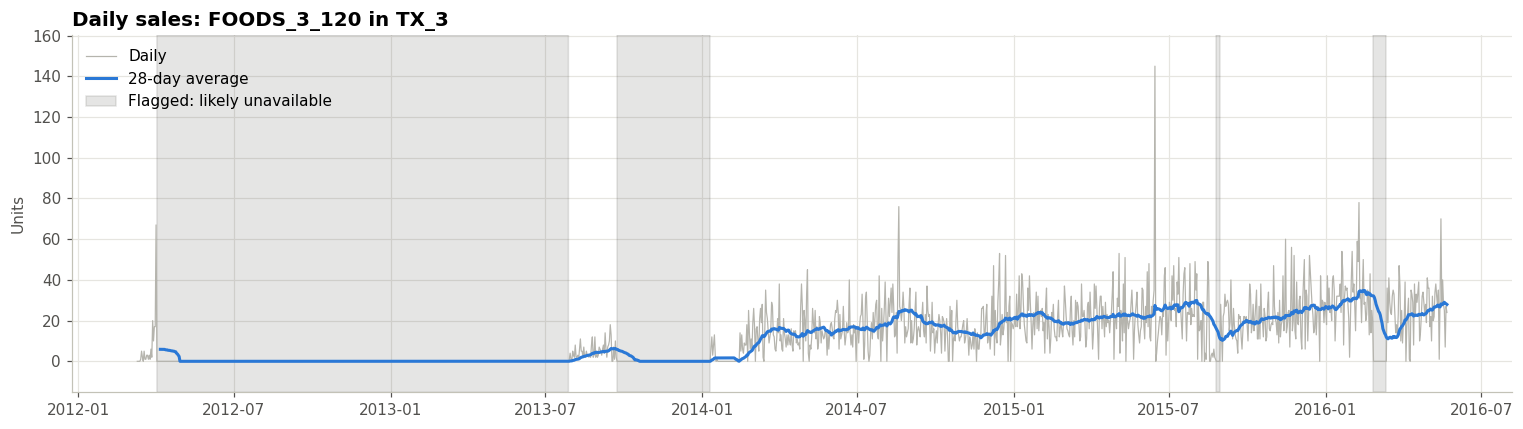

Saved: /content/drive/MyDrive/m5-inventory/reports/figures/02_05_unavailable_FOODS_3_090_TX_2.png


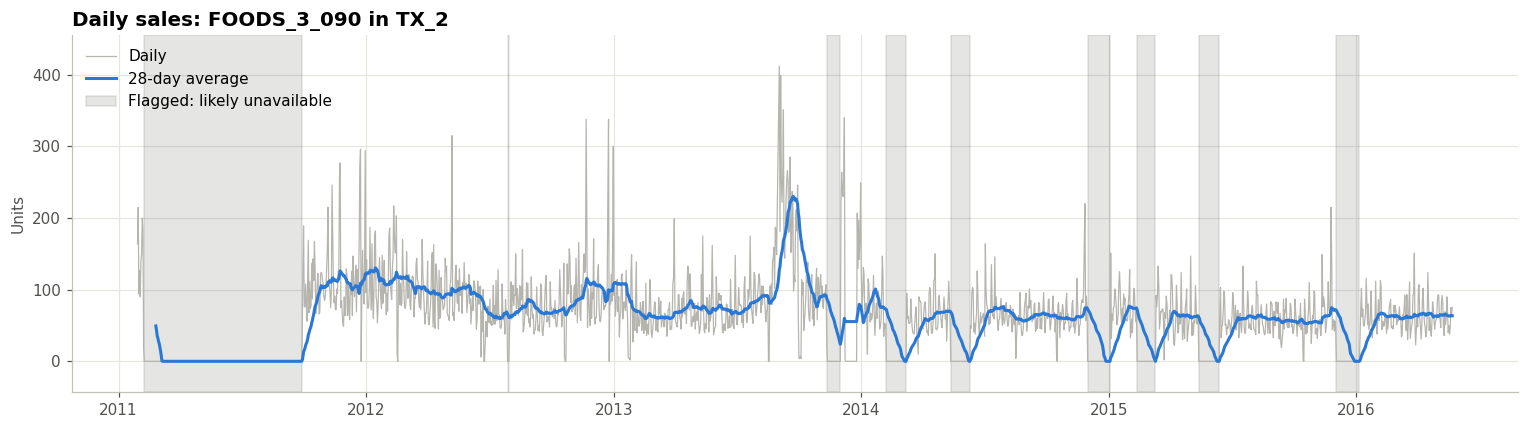

In [40]:
examples = [('FOODS_3_120', 'TX_3'), ('FOODS_3_090', 'TX_2')]

for item, store in examples:
    fig = plot_series(item, store)
    ax = fig.axes[0]

    sub = df.loc[(df['item_id'] == item) & (df['store_id'] == store)].set_index('date')
    ax.fill_between(sub.index, 0, 1, where=sub['unavailable'],
                    transform=ax.get_xaxis_transform(),
                    color='#52514e', alpha=0.15, step='mid',
                    label='Flagged: likely unavailable')
    ax.legend(loc='upper left')

    save_fig(fig, f'02_05_unavailable_{item}_{store}')
    plt.show()

In [41]:
FLAGGED_FILE = os.path.join(PROJECT_DIR, 'data', 'processed', 'm5_tx_foods_long_flagged.parquet')
df.to_parquet(FLAGGED_FILE, index=False)
print(f"Saved: {FLAGGED_FILE} ({os.path.getsize(FLAGGED_FILE) / 1e6:.1f} MB)")

Saved: /content/drive/MyDrive/m5-inventory/data/processed/m5_tx_foods_long_flagged.parquet (25.4 MB)


In [42]:
# Diagnostic: how much of each product's history is flagged, by how fast it sells?
flag_share = df.groupby(['item_id', 'store_id'], observed=True)['unavailable'].mean().rename('flag_share')
diag = series_stats.join(flag_share, on=['item_id', 'store_id'])

diag['speed'] = pd.cut(diag['mean_daily'],
                       bins=[0, 0.5, 1, 3, 10, np.inf],
                       labels=['<0.5/day', '0.5–1/day', '1–3/day', '3–10/day', '10+/day'])

diag.groupby('speed', observed=True).agg(
    products          = ('flag_share', 'size'),
    median_zero_share = ('zero_share', 'median'),
    median_flag_share = ('flag_share', 'median'),
).round(3)

,products,median_zero_share,median_flag_share
speed,,,
<0.5/day,1484,0.791,0.173
0.5–1/day,1087,0.601,0.110
1–3/day,1157,0.405,0.097
3–10/day,474,0.199,0.084
10+/day,109,0.118,0.079


              streaks    days  share_of_flagged_days
length_group                                        
≤7 days          1956   10537                  0.010
8–14             1881   20433                  0.019
15–30            2611   57950                  0.054
31–90            4357  258002                  0.243
91–365           3691  561102                  0.528
365+              293  155451                  0.146 

Slow sellers (<0.5/day) with at least one flag: 1,248
FOODS_3_046 in TX_3: avg 0.29/day, 8% of days flagged


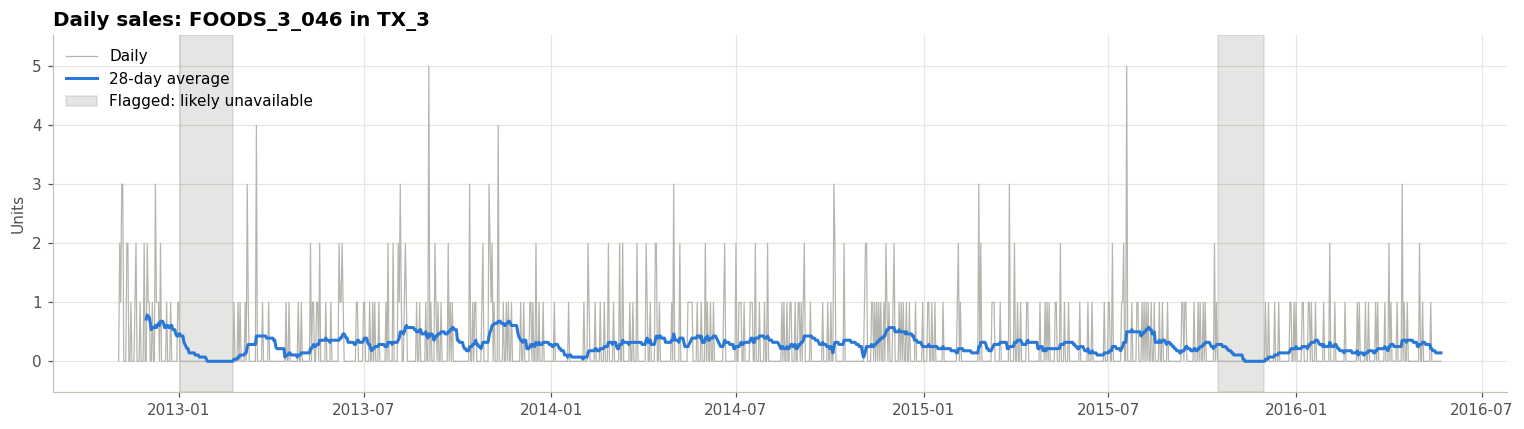

FOODS_3_337 in TX_3: avg 0.30/day, 14% of days flagged


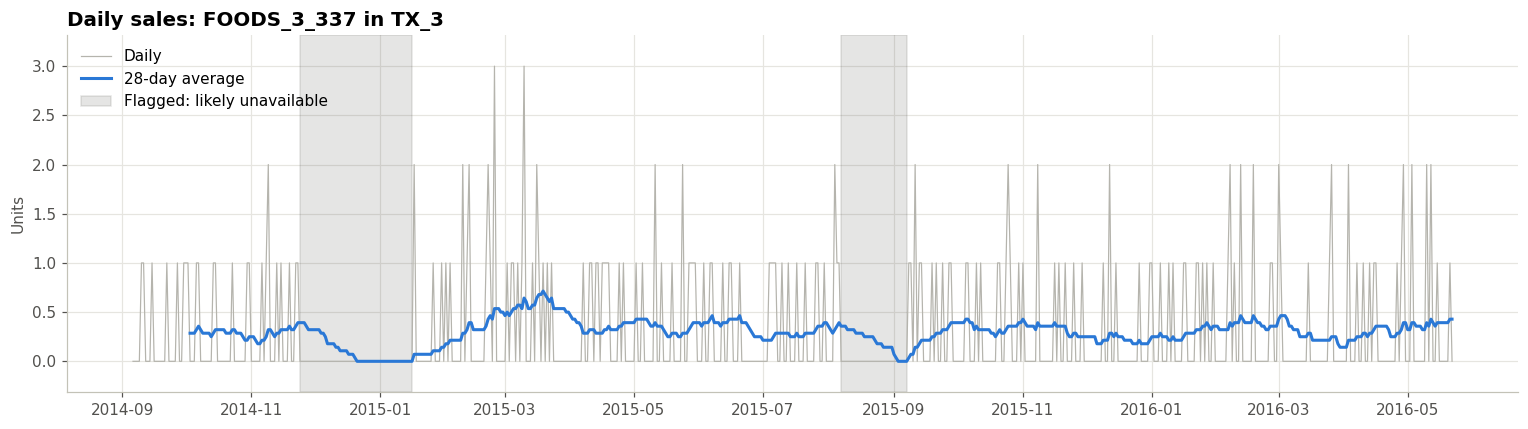

FOODS_3_365 in TX_2: avg 0.40/day, 2% of days flagged


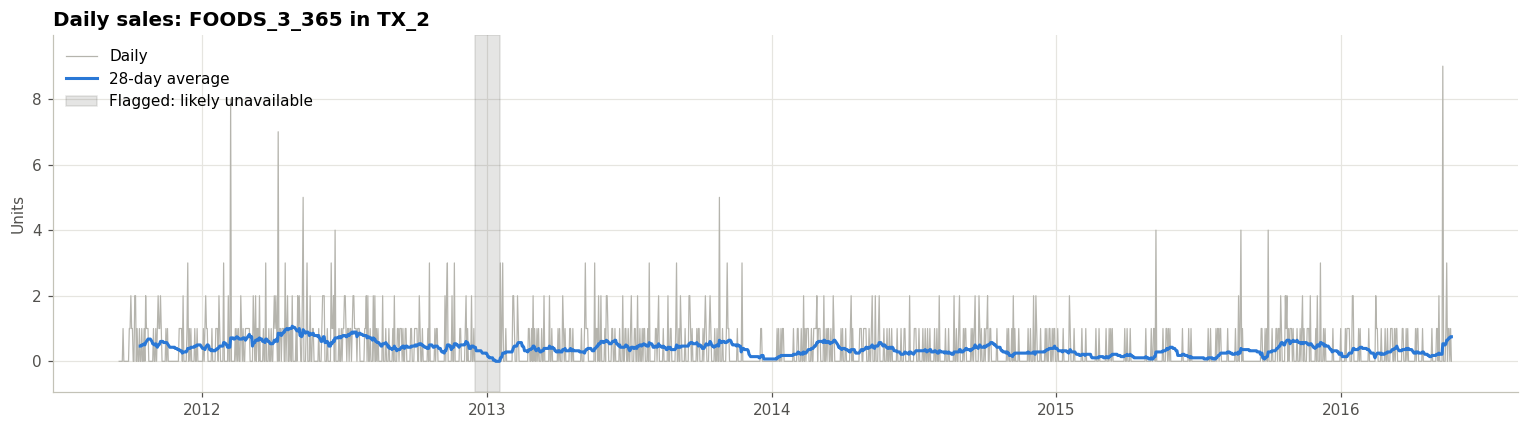

In [43]:
# 1) Which streak lengths make up the flagged days?
fl = runs[runs['unavailable']].copy()
fl['length_group'] = pd.cut(fl['length'], bins=[0, 7, 14, 30, 90, 365, np.inf],
                            labels=['≤7 days', '8–14', '15–30', '31–90', '91–365', '365+'])
by_length = fl.groupby('length_group', observed=True).agg(streaks=('length', 'size'),
                                                         days=('length', 'sum'))
by_length['share_of_flagged_days'] = (by_length['days'] / by_length['days'].sum()).round(3)
print(by_length.to_string(), "\n")

# 2) A helper that plots one product with its flagged days shaded
def plot_flagged(item_id, store_id):
    fig = plot_series(item_id, store_id)
    ax = fig.axes[0]
    sub = df.loc[(df['item_id'] == item_id) & (df['store_id'] == store_id)].set_index('date')
    ax.fill_between(sub.index, 0, 1, where=sub['unavailable'],
                    transform=ax.get_xaxis_transform(),
                    color='#52514e', alpha=0.15, step='mid', label='Flagged: likely unavailable')
    ax.legend(loc='upper left')
    return fig

# 3) Three RANDOM slow sellers that have at least one flag
slow_flagged = diag[(diag['mean_daily'] < 0.5) & (diag['flag_share'] > 0)]
print(f"Slow sellers (<0.5/day) with at least one flag: {len(slow_flagged):,}")

for _, row in slow_flagged.sample(3, random_state=42).iterrows():
    print(f"{row['item_id']} in {row['store_id']}: avg {row['mean_daily']:.2f}/day, "
          f"{row['flag_share']:.0%} of days flagged")
    fig = plot_flagged(row['item_id'], row['store_id'])
    plt.show()

### Step 3b — Result

- The revised rule flags **14,789 zero streaks** — 1.06M days (**15.7% of rows, 28.7% of zero-sales rows**) across 3,824 of 4,311 products.
- **Flags are dominated by long absences:** 67% of flagged days come from streaks longer than 90 days and 91% from streaks longer than 30 days. Short streaks (≤ 14 days, treated as stockouts) are only ~3% of flagged days: 3,837 streaks with an estimated **~120K units of lost sales (0.9% of units sold)**.
- **Slow sellers are flagged most** (median 17% of days for < 0.5 units/day vs. 8% for 10+/day). A **random spot check** of three flagged slow sellers (`random_state=42`) found the flagged stretches are the only periods where the 28-day average reaches zero and are clearly longer than each product's usual gaps — consistent with genuine absence (slow movers plausibly get lower restocking priority). One case (FOODS_3_365, TX_2, ~3 weeks around New Year 2013) is borderline.
- **Demand stays highly intermittent after cleaning:** the zero-sales share falls only from 54.7% to **46.2%** once flagged days are excluded.

→ *Rule locked in; flags saved to `m5_tx_foods_long_flagged.parquet`. Sensitivity to the threshold will be checked during modelling.*